# Spectrogram dataset generator for RF protocol detection and classification (LTE, DMR, P25, TETRA)

Everything is **synthetic and labeled automatically**: the generator knows the exact parameters of every signal it creates. The task is to **detect** each transmission (a time-frequency box) and **classify its protocol**.

| Item | Value |
|---|---|
| Band / receiver model | UHF, USRP-like (12/14-bit ADC, TCXO offset, IQ imbalance, DC spike, band-edge roll-off) |
| Sample rate | 2.56 MS/s complex (2.56 MHz of spectrum per image) |
| Spectrogram | N_fft = 2048 (1250 Hz bins, 0.8 ms window), hop 1024 (0.4 ms), 192 frames (about 77 ms) |
| SNR | 5 to 30 dB in-band (out-of-range stress set kept separate). `train` is skewed towards low SNR (truncated exponential); `val` and all test sets are uniform |
| Protocols (classes) | **LTE** (downlink OFDM, 1.4 MHz), **DMR** (4FSK, 12.5 kHz, 2-slot TDMA), **P25** phase 1 (C4FM, 12.5 kHz, continuous), **TETRA** (pi/4-DQPSK, 25 kHz, 4-slot TDMA) |
| Held out (open-set only) | NBFM (analog voice), WFM (broadcast FM), GSM (GMSK, 8-slot TDMA) |

Waveforms live in `protocols.py` (each protocol is built at its native rate with its real symbol clock, framing and sync words, then resampled to 2.56 MS/s).

**Sets written:** `train`, `val`, `test` (split by session group, no leakage) and the frozen evaluation sets `test_robust` (unseen receiver impairments), `test_openset` (held-out protocols NBFM, WFM, GSM), `test_snr_stress` (SNR outside 5 to 30 dB).

**How to use:** run all cells top to bottom. Choose the size with the environment variable `SPECTRUM_PROFILE` (`smoke` about 1 minute, `pilot` about 12k scenes, `main` about 95k scenes). Array layout is `[time frame, frequency bin]`, so a spectrogram is a 192 x 2048 image, directly usable as COCO / YOLO input.

In [1]:
import os
for _v in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "VECLIB_MAXIMUM_THREADS", "MKL_NUM_THREADS"):
    os.environ.setdefault(_v, "1")          # one BLAS/FFT thread per worker process
import json, math, time, hashlib, platform, datetime, warnings
import multiprocessing as mp
from pathlib import Path
from dataclasses import dataclass, asdict
from functools import lru_cache
import sys
sys.path.insert(0, str(Path.cwd()))          # protocols.py lives next to this notebook

import numpy as np
import pandas as pd
import scipy
from scipy.signal import fftconvolve, get_window
from numpy.lib.stride_tricks import sliding_window_view
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

from protocols import PROTOCOLS, UNKNOWN_PROTOCOLS, gen_protocol, plan_activity, MERGE_GAP_S, rrc_taps

try:
    from tqdm.auto import tqdm
except ImportError:                          # progress bars are optional
    def tqdm(x, **kw):
        return x

warnings.filterwarnings("ignore", category=DeprecationWarning, message=".*fork.*")
print("numpy", np.__version__, "| scipy", scipy.__version__, "| pandas", pd.__version__, "| python", platform.python_version())

numpy 2.5.4 | scipy 1.18.1 | pandas 3.1.0 | python 3.12.11


/Users/tohid/Desktop/RF-Signal-Detection/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Configuration

All parameters that define the dataset live here and are written to `config.json` next to the data, so every set is traceable to a generator version and seed.

In [2]:
PROFILE = os.environ.get("SPECTRUM_PROFILE", "pilot")        # "smoke" | "pilot" | "main"
STORE_IQ = os.environ.get("SPECTRUM_STORE_IQ", "0") == "1"   # raw IQ is 0.8 MB per scene at 2.56 MS/s, so it is off by default
N_WORKERS = int(os.environ.get("SPECTRUM_WORKERS", max(1, (os.cpu_count() or 2) - 1)))
REBUILD = set(filter(None, os.environ.get("SPECTRUM_REBUILD", "").split(",")))   # set names to regenerate
FORCE_FROZEN = os.environ.get("SPECTRUM_FORCE_FROZEN", "0") == "1"                # needed to regenerate a frozen test set

SET_SIZES_BY_PROFILE = {
    "smoke": dict(train=160,    val=40,    test=40,    test_robust=40,   test_openset=40,   test_snr_stress=40),
    "pilot": dict(train=8000,   val=1500,  test=1500,  test_robust=1000, test_openset=1000, test_snr_stress=1000),
    "main":  dict(train=60000,  val=10000, test=10000, test_robust=5000, test_openset=5000, test_snr_stress=5000),
}
SET_SIZES = SET_SIZES_BY_PROFILE[PROFILE]
SET_IDS = {name: i for i, name in enumerate(SET_SIZES)}      # stable ids used for seeding
FROZEN_SETS = {"test", "test_robust", "test_openset", "test_snr_stress"}
SET_MODE = {"test_openset": "openset", "test_snr_stress": "snr_stress"}   # default: "general"


@dataclass(frozen=True)
class Cfg:
    version: str = "0.3.0"
    base_seed: int = 20261113

    fs: float = 2_560_000.0
    n_fft: int = 2048
    hop: int = 1024
    n_frames: int = 192
    # --- SNR: in-band SNR over the occupied bandwidth, reference bandwidth floored at ref_bw_min_hz
    snr_range: tuple = (5.0, 30.0)
    snr_tau_train: float = 8.0       # dB; train SNR ~ truncated exponential from 5 dB (about 75% of signals below 15 dB). None = uniform. val/test stay uniform
    snr_stress_ranges: tuple = ((-5.0, 5.0), (30.0, 35.0))
    ref_bw_min_hz: float = 500.0
    obw_fraction: float = 0.99
    # --- storage
    db_min: float = -20.0            # spectrogram stored as uint8 dB relative to the noise floor
    db_max: float = 60.0
    group_size: int = 50             # scenes per "capture session" (shared receiver state); splits never cut a group
    shard_size: int = 100
    # --- scene composition
    n_signals_probs: tuple = (0.10, 0.35, 0.30, 0.20, 0.05)       # 0..4 signals per scene (at most one LTE: a second 1.4 MHz carrier does not fit)
    guard_hz: float = 250_000.0      # keep signals this far from the band edge: the receiver roll-off starts at 80% of the half band (1.02 MHz)
    min_sep_hz: float = 15_000.0     # minimum gap between the occupied bands of two signals (labels never overlap)
    hard_negative_prob: float = 0.15
    adc_headroom_db: float = 12.0

    @property
    def n_samples(self):
        return (self.n_frames - 1) * self.hop + self.n_fft

    @property
    def df(self):
        return self.fs / self.n_fft


CFG = Cfg()
FS, NS, DF = CFG.fs, CFG.n_samples, CFG.df
OUT_DIR = Path(os.environ.get("SPECTRUM_OUT", "dataset")) / f"spectrum_rf_v{CFG.version}_{PROFILE}"
print(f"profile={PROFILE}  scenes={sum(SET_SIZES.values()):,}  workers={N_WORKERS}  store_iq={STORE_IQ}")
print(f"samples/scene={NS}  duration={NS / FS * 1e3:.1f} ms  bin width={DF:.0f} Hz  window={CFG.n_fft / FS * 1e3:.2f} ms  out={OUT_DIR}")

profile=pilot  scenes=14,000  workers=14  store_iq=False
samples/scene=197632  duration=77.2 ms  bin width=1250 Hz  window=0.80 ms  out=dataset/spectrum_rf_v0.3.0_pilot


## 2. Class registry and label hierarchy

Each signal has three labels: the **fine class** and the **protocol** (here identical: LTE, DMR, P25, TETRA; this is the primary classification target, stored in the `family` column), and a **coarse group** (Wideband = LTE, Narrowband = DMR / P25 / TETRA). The three held-out protocols appear **only** in `test_openset`.

In [3]:
CLASS_TABLE = [   # id, name, family (= protocol), coarse group
    (0, "LTE", "LTE", "Wideband"),
    (1, "DMR", "DMR", "Narrowband"),
    (2, "P25", "P25", "Narrowband"),
    (3, "TETRA", "TETRA", "Narrowband"),
]
UNKNOWN_TABLE = [   # held out for open-set evaluation only
    (4, "NBFM", "UNKNOWN", "Unknown"),
    (5, "WFM", "UNKNOWN", "Unknown"),
    (6, "GSM", "UNKNOWN", "Unknown"),
]
FAMILIES = ["LTE", "DMR", "P25", "TETRA"]
FAMILY_ID = {"LTE": 1, "DMR": 2, "P25": 3, "TETRA": 4, "UNKNOWN": 5}     # 0 = background / noise only
COARSE_ID = {"Wideband": 1, "Narrowband": 2, "Unknown": 3}
CLASS = {name: dict(id=i, name=name, family=fam, coarse=coarse) for i, name, fam, coarse in CLASS_TABLE + UNKNOWN_TABLE}
KNOWN = [r[1] for r in CLASS_TABLE]
UNKNOWN = [r[1] for r in UNKNOWN_TABLE]
UNKNOWN_ID = FAMILY_ID["UNKNOWN"]
FAMILY_MEMBERS = {f: [n for n in KNOWN if CLASS[n]["family"] == f] for f in FAMILIES}
assert KNOWN == PROTOCOLS and UNKNOWN == UNKNOWN_PROTOCOLS

# optional: oversample protocols in the TRAIN set only, e.g. SPECTRUM_TRAIN_BOOST="DMR=2,P25=2" (default: off, uniform)
TRAIN_BOOST = {k: float(v) for k, v in (kv.split("=") for kv in filter(None, os.environ.get("SPECTRUM_TRAIN_BOOST", "").split(",")))}


def sample_known_class(rng, boost=None):
    # protocol-balanced: pick a protocol uniformly (or with `boost` weights)
    if boost:
        w = np.array([boost.get(f, 1.0) for f in FAMILIES], dtype=float)
        fam = FAMILIES[int(rng.choice(len(FAMILIES), p=w / w.sum()))]
    else:
        fam = FAMILIES[int(rng.integers(len(FAMILIES)))]
    members = FAMILY_MEMBERS[fam]
    return members[int(rng.integers(len(members)))]

pd.DataFrame(CLASS_TABLE + UNKNOWN_TABLE, columns=["id", "class", "family", "coarse"])

,id,class,family,coarse
0,0,LTE,LTE,Wideband
1,1,DMR,DMR,Narrowband
2,2,P25,P25,Narrowband
3,3,TETRA,TETRA,Narrowband
4,4,NBFM,UNKNOWN,Unknown
5,5,WFM,UNKNOWN,Unknown
6,6,GSM,UNKNOWN,Unknown


## 3. Protocol generators (complex baseband at 2.56 MS/s)

The waveforms are implemented in `protocols.py`. Each returns a complex baseband signal centered at 0 Hz for the whole scene length; the burst structure comes from `plan_activity` (Section 4), and the signal is scaled, faded and shifted in the scene composer (Section 6).

| Protocol | Modulation and framing |
|---|---|
| **LTE** | downlink OFDM, 1.4 MHz (72 subcarriers x 15 kHz, FFT 128 at 1.92 MS/s), normal / extended cyclic prefix, PDCCH over the whole band in the first 1 to 3 symbols of every 1 ms subframe, PDSCH QPSK / 16QAM / 64QAM on a random share of the resource blocks, cell reference signals on every 6th subcarrier, PSS / SSS every 5 ms, FDD (continuous) or TDD (uplink subframes silent) |
| **DMR** | 4FSK, 4800 sym/s, deviation +-648 / +-1944 Hz (RC pulse, alpha 0.2), 2-slot TDMA (30 ms slots, 144 symbols) with the ETSI sync words in the middle of each slot. Repeater downlink is continuous, mobile uplink is 27.5 ms bursts in one or both slots |
| **P25** | phase 1 C4FM, 4800 sym/s, deviation +-600 / +-1800 Hz, continuous transmission, 48-bit frame sync every 180 ms |
| **TETRA** | pi/4-DQPSK, 18 ksym/s, root-raised-cosine 0.35 (25 kHz channel), 4-slot TDMA (14.167 ms slots, 56.67 ms frame). Base station main carrier continuous; traffic carriers and mobiles use one to three slots |
| NBFM, WFM, GSM | held out: analog voice FM (+-2.5 / 5 kHz), broadcast FM (+-50 to 75 kHz), GMSK 270.8 kbaud in 8-slot TDMA |

Known limit: DMR downlink and P25 are both continuous 4800-baud 4-level FSK of the same bandwidth. At 1250 Hz bin width they differ only by about 8% in deviation, so they are separable mainly through burst timing (DMR mobile bursts) and fine spectral shape.

In [4]:
def log_uniform(rng, lo, hi):
    return float(np.exp(rng.uniform(np.log(lo), np.log(hi))))


def gen_signal(rng, cls, n):
    # returns (complex64 baseband of length n centered at 0 Hz, info dict of the drawn parameters)
    return gen_protocol(rng, cls, n, FS)

## 4. Time structure and envelopes

`plan_activity` (in `protocols.py`) returns two interval lists per signal:

- **envelope intervals**: what is physically on the air, for example each 27.5 ms DMR mobile burst or each TETRA slot;
- **label intervals**: bursts separated by less than 5 ms are one transmission, so one box (a repeater's continuous 2-slot downlink, a TETRA carrier with all slots active, an LTE TDD cell).

| Protocol | Envelope |
|---|---|
| LTE | continuous (TDD gaps are inside the signal) |
| DMR | downlink: continuous call; uplink: 27.5 ms bursts every 60 ms in one slot, or in both slots (merged); a call spans the scene or starts / stops inside it |
| P25 | continuous call (spans the scene, or starts / stops inside it) |
| TETRA | main carrier continuous; traffic carrier with 1 to 3 active slots; mobile uplink 0.93 x slot bursts |

Edges use raised-cosine ramps (0.3 ms, about 5 TETRA symbols) to avoid key clicks.

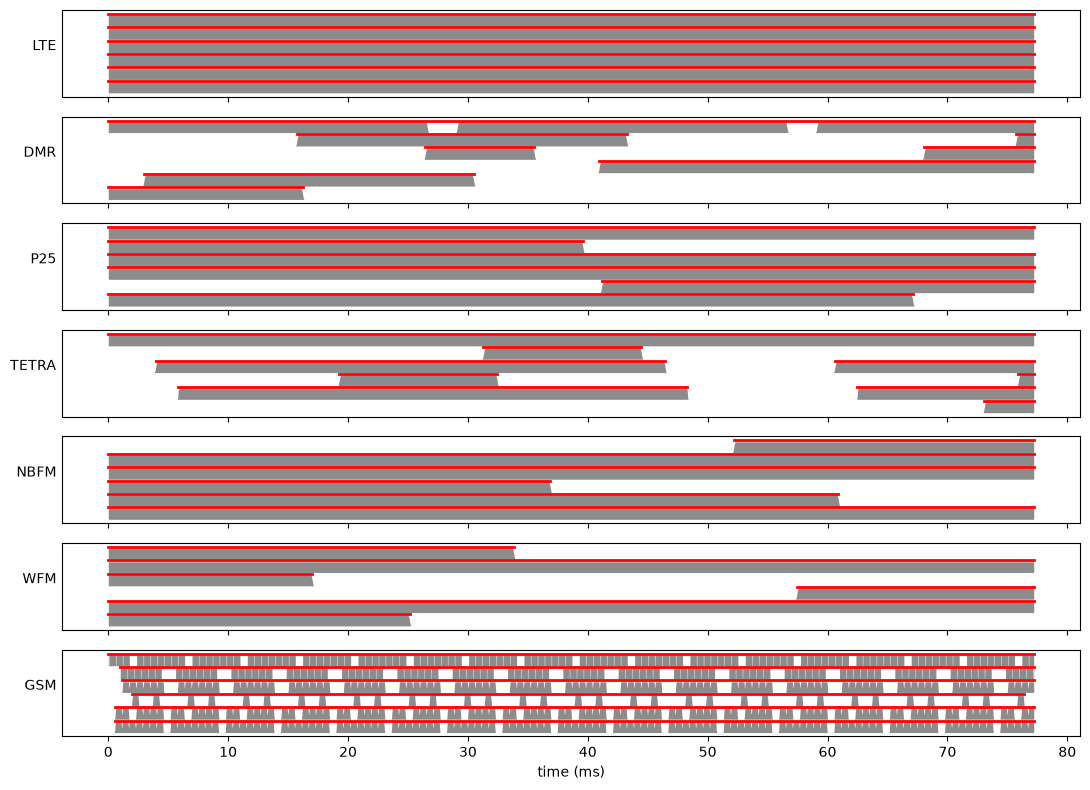

In [5]:
def _ms(v):
    return int(round(v * 1e-3 * FS))


def envelope_from_intervals(ints, n):
    ind = np.zeros(n, dtype=np.float64)
    for a, b in ints:
        ind[a:b] = 1.0
    shortest = min(b - a for a, b in ints)
    r = max(3, min(_ms(0.3), int(0.25 * shortest))) | 1                   # odd ramp length
    kern = np.hanning(r + 2)[1:-1]
    kern /= kern.sum()
    padded = np.pad(ind, r // 2, mode="edge")                             # no artificial ramp at the scene edge
    return np.convolve(padded, kern, mode="valid").astype(np.float32)


def obw_bounds(y, frac=CFG.obw_fraction, nfft=1 << 18):
    # 99%-power occupied bandwidth of the ideal (noise-free) signal: lower and upper frequency
    assert len(y) <= nfft
    Y = np.fft.fftshift(np.fft.fft(y, nfft))
    p = (Y.real ** 2 + Y.imag ** 2)
    c = np.cumsum(p) / p.sum()
    freqs = (np.arange(nfft) - nfft // 2) * FS / nfft
    lo = freqs[min(np.searchsorted(c, (1 - frac) / 2), nfft - 1)]
    hi = freqs[min(np.searchsorted(c, 1 - (1 - frac) / 2), nfft - 1)]
    return float(lo), float(hi)


# quick look at the envelopes (grey = on the air, red = label intervals = boxes), seven draws per protocol
_rng = np.random.default_rng(1)
fig, ax = plt.subplots(len(KNOWN + UNKNOWN), 1, figsize=(11, 8), sharex=True)
for a, name in zip(ax, KNOWN + UNKNOWN):
    for k in range(6):
        env_i, lab_i, _info = plan_activity(_rng, name, NS, FS)
        a.fill_between(np.arange(NS) / FS * 1e3, k, k + 0.8 * envelope_from_intervals(env_i, NS), color="0.55", lw=0)
        for s0, s1 in lab_i:
            a.plot([s0 / FS * 1e3, s1 / FS * 1e3], [k + 0.9] * 2, color="red", lw=2)
    a.set_yticks([])
    a.set_ylabel(name, rotation=0, ha="right")
ax[-1].set_xlabel("time (ms)")
plt.tight_layout()
plt.show()

## 5. Receiver model and spectrogram

A **single STFT implementation** is used for generation, QA and (later) training and inference, so train/serve skew cannot occur.

Spectrogram values are stored as `uint8` dB **relative to the expected noise floor** (0 dB = unit-variance complex noise, the same reference for every scene), quantized between `db_min` and `db_max`.

Receiver chain applied to each scene (R&D 3.3): signals (faded, frequency-shifted by the transmitter offset and the receiver's common frequency offset) + AWGN + optional hard negatives, then band-edge roll-off, IQ imbalance, DC offset and an AGC + ADC quantizer (8, 12 or 14 bit).

In [6]:
WIN = get_window("hann", CFG.n_fft).astype(np.float32)
WIN_ENERGY = float(np.sum(WIN.astype(np.float64) ** 2))


def spectrogram_pow(x):
    # linear power, shape [frames, bins], bins in ascending frequency (-fs/2 .. +fs/2), 1.0 = unit-variance noise floor
    fr = sliding_window_view(x, CFG.n_fft)[::CFG.hop]
    X = np.fft.fft(fr * WIN, axis=-1)
    return np.fft.fftshift(X.real ** 2 + X.imag ** 2, axes=-1) / WIN_ENERGY


def spectrogram_db(x):
    return (10 * np.log10(spectrogram_pow(x) + 1e-12)).astype(np.float32)


DB_STEP = (CFG.db_max - CFG.db_min) / 255.0


def quantize_db(db):
    return np.clip(np.round((db - CFG.db_min) / DB_STEP), 0, 255).astype(np.uint8)


def dequantize_db(q):
    return q.astype(np.float32) * DB_STEP + CFG.db_min


@lru_cache(maxsize=4)
def rx_filter_response(n):
    # flat to 80% of the band, then a raised-cosine roll-off to -20 dB at the band edge (analog + decimation filter)
    a = np.abs(np.fft.fftfreq(n, 1 / FS)) / (FS / 2)
    h = np.ones(n)
    m = a > 0.8
    h[m] = 0.1 + 0.9 * 0.5 * (1 + np.cos(np.pi * (a[m] - 0.8) / 0.2))
    return h


def fading_gain(rng, n, level):
    # flat fading (narrowband VHF/UHF): 0 none, 1 Rician K=10 dB, 2 Rician K=3 dB, 3 Rayleigh. Unit mean power.
    if level == 0:
        return np.ones(n, dtype=np.complex64)
    K = {1: 10 ** 1.0, 2: 10 ** 0.3, 3: 0.0}[level]
    fd, m = rng.uniform(2, 20), 16
    t_lo = np.arange(0.0, n / FS + 2e-3, 1e-3)                         # Doppler is below 20 Hz: compute at 1 kHz, interpolate to fs
    ang, ph = rng.uniform(0, 2 * np.pi, m), rng.uniform(0, 2 * np.pi, m)
    d_lo = np.exp(1j * (2 * np.pi * fd * np.cos(ang)[:, None] * t_lo[None, :] + ph[:, None])).sum(0) / np.sqrt(m)
    t = np.arange(n) / FS
    diffuse = np.interp(t, t_lo, d_lo.real) + 1j * np.interp(t, t_lo, d_lo.imag)
    return (np.sqrt(K / (K + 1)) + np.sqrt(1 / (K + 1)) * diffuse).astype(np.complex64)


def adc_quantize(x, bits, headroom_db):
    # AGC puts full scale at headroom_db above the composite rms, then rounds to `bits` bits (I and Q separately).
    rms = np.sqrt(np.mean(np.abs(x) ** 2))
    fs_amp = rms * 10 ** (headroom_db / 20)
    step = 2 * fs_amp / 2 ** bits
    lim = 2 ** (bits - 1)
    qi = np.clip(np.round(x.real / step), -lim, lim - 1).astype(np.int32)
    qr = np.clip(np.round(x.imag / step), -lim, lim - 1).astype(np.int32)
    shift = 16 - bits                                       # store left-aligned in int16
    iq = np.stack([qi << shift, qr << shift], axis=-1).astype(np.int16)
    return iq, float(step / 2 ** shift)                     # int16 LSB -> noise-floor units


def iq_to_complex(iq, scale):
    return ((iq[..., 0].astype(np.float32) + 1j * iq[..., 1].astype(np.float32)) * scale).astype(np.complex64)


def to_pixel_box(f_lo, f_hi, s0, s1):
    # frequency bins covered by [f_lo, f_hi]; time frames whose window CENTER lies inside the on-interval (min 2 frames)
    F, T = CFG.n_fft, CFG.n_frames
    i0 = int(np.clip(round(f_lo / DF + F / 2), 0, F - 1))
    i1 = int(np.clip(max(round(f_hi / DF + F / 2), i0), 0, F - 1))
    k0 = max(int(np.ceil((s0 - CFG.n_fft / 2) / CFG.hop)), 0)
    k1 = min(int(np.floor((s1 - 1 - CFG.n_fft / 2) / CFG.hop)), T - 1)
    if k1 < k0 + 1:
        k0 = max(0, min(k0, T - 2))
        k1 = k0 + 1
    return i0, k0, i1, k1

## 6. Scene composer

Scene modes:

- **general**: 0 to 4 signals (protocol-balanced, at most one LTE, SNR in 5 to 30 dB). In `train` the SNR density falls with SNR (more low-SNR data); `val`/`test` draw it uniformly so every SNR bin has enough samples for per-SNR reporting.
- **openset**: 1 to 3 signals, at least one from a held-out protocol (NBFM, WFM, GSM).
- **snr_stress**: SNR drawn outside 5 to 30 dB (robustness reporting only).

Signals never overlap in frequency (at least 15 kHz between occupied bands), so every box has exactly one protocol.

**SNR convention:** `0.99 * P_on / (sigma^2 * B_ref / fs) = SNR`, with `sigma^2 = 1`, `P_on` the mean power while the signal is on, and `B_ref = max(OBW, 500 Hz)`. It is the SNR over the occupied bandwidth, so a 1 MHz LTE carrier and a 7 kHz DMR channel with the same SNR differ by 20 dB in per-bin level: narrowband signals are much harder to see.

**Labels** are derived from the generator state: box frequency = the lower and upper bounds that hold 99% of the noise-free signal power, minimum one bin; box time = frames whose window center lies inside a label interval (bursts closer than 5 ms are merged, so a transmission is one box; the isolated bursts of a mobile are separate boxes).

In [7]:
def sample_snr(rng, lo, hi, tau=None):
    # uniform in [lo, hi], or a truncated exponential from lo with scale tau (dB). Both consume exactly one rng draw,
    # so switching a set between them never shifts the random stream of anything else in the scene.
    u = rng.uniform()
    if tau is None:
        return float(lo + u * (hi - lo))
    return float(lo - tau * np.log(1.0 - u * (1.0 - np.exp(-(hi - lo) / tau))))


def plan_scene(rng, spec):
    mode, forced = spec["mode"], spec.get("force")
    plans = []
    snr_lo, snr_hi = CFG.snr_range
    if forced:                                              # explicit classes (previews and unit tests); optional fc_hz = nominal center frequency
        for f in forced:
            plans.append(dict(cls=f["cls"], snr=f["snr_db"], fc_hz=f.get("fc_hz")))
    elif mode == "openset":
        for k in range(int(rng.integers(1, 4))):
            unk = (k == 0) or rng.random() < 0.3
            c = UNKNOWN[int(rng.integers(len(UNKNOWN)))] if unk else sample_known_class(rng)
            plans.append(dict(cls=c, snr=float(rng.uniform(snr_lo, snr_hi)), fc_hz=None))
    else:
        n_sig = int(rng.choice(len(CFG.n_signals_probs), p=CFG.n_signals_probs)) if mode == "general" else int(rng.integers(1, 4))
        snr_tau = CFG.snr_tau_train if (spec["set"] == "train" and mode == "general") else None
        for _ in range(n_sig):
            if mode == "snr_stress":
                lo, hi = CFG.snr_stress_ranges[int(rng.integers(len(CFG.snr_stress_ranges)))]
            else:
                lo, hi = snr_lo, snr_hi
            plans.append(dict(cls=sample_known_class(rng, TRAIN_BOOST if spec["set"] == "train" and mode == "general" else None),
                              snr=sample_snr(rng, lo, hi, snr_tau), fc_hz=None))
    seen_lte = False
    for p in plans:                                         # a second 1.4 MHz LTE carrier would not fit next to the first one
        if p["cls"] == "LTE":
            if seen_lte:
                p["cls"] = [n for n in KNOWN if n != "LTE"][int(rng.integers(len(KNOWN) - 1))]
            seen_lte = True
    return plans


def snr_amplitude(obw, p_on, snr_db):
    # amplitude that gives the requested in-band SNR against unit-variance complex noise (see convention above)
    b_ref = max(obw, CFG.ref_bw_min_hz)
    return float(np.sqrt(10 ** (snr_db / 10) * b_ref / FS / (CFG.obw_fraction * p_on))), b_ref


def burst_type_of(lab_ints, k):
    a, b = lab_ints[k]
    if len(lab_ints) > 1:
        return "train"
    d = (b - a) / FS
    return "continuous" if (a <= 0 and b >= NS) else ("long" if d >= 30e-3 else ("short" if d >= 10e-3 else "very_short"))


def make_scene(spec, keep_components=False):
    cfg = CFG
    rng = np.random.default_rng(spec["seed"])
    sess = spec["session"]
    plans = plan_scene(rng, spec)

    # 1) generate every signal: baseband, envelope, occupied bandwidth, SNR scaling, fading
    sigs = []
    for p in plans:
        env_ints, lab_ints, ainfo = plan_activity(rng, p["cls"], NS, FS)
        env = envelope_from_intervals(env_ints, NS)
        x, info = gen_signal(rng, p["cls"], NS)
        info.update(ainfo)
        y = x * env
        p_on = float(np.sum(np.abs(y) ** 2) / np.sum(env.astype(np.float64) ** 2))
        lo, hi = obw_bounds(y)
        obw = hi - lo
        amp, b_ref = snr_amplitude(obw, p_on, p["snr"])
        z = (y * amp * fading_gain(rng, NS, sess["fading_level"])).astype(np.complex64)
        sigs.append(dict(plan=p, ints=lab_ints, info=info, z=z, obw=obw, lo=lo, hi=hi, ext=max(abs(lo), abs(hi)), b_ref=b_ref))

    # 2) place the signals in frequency, without overlap
    placed = []
    for s in sigs:
        if s["plan"].get("fc_hz") is not None:             # forced center frequency (inference demos), no random offset
            s["fc_nom"], s["tx_off"] = float(s["plan"]["fc_hz"]), 0.0
            placed.append((s["fc_nom"] + s["lo"], s["fc_nom"] + s["hi"]))
            continue
        allowed = max(0.0, FS / 2 - cfg.guard_hz - s["ext"])
        tx = float(np.clip(rng.normal(0, 300.0), -1000, 1000))
        for _ in range(60):
            fc = float(rng.uniform(-allowed, allowed))
            lo_, hi_ = fc + tx + s["lo"], fc + tx + s["hi"]
            if all(hi_ + cfg.min_sep_hz < a or lo_ - cfg.min_sep_hz > b for a, b in placed):
                break
        placed.append((lo_, hi_))
        s["fc_nom"], s["tx_off"] = fc, tx
    cfo = float(sess["cfo_hz"] + rng.normal(0, 20.0))        # receiver common offset (oscillator ppm x carrier)
    t = np.arange(NS) / FS
    sig_sum = np.zeros(NS, dtype=np.complex64)
    comps = []
    for s in sigs:
        s["fc"] = s["fc_nom"] + s["tx_off"] + cfo
        zs = (s["z"] * np.exp(2j * np.pi * s["fc"] * t)).astype(np.complex64)
        sig_sum += zs
        if keep_components:
            comps.append(zs)

    # 3) noise and hard negatives (spurs and impulses are NOT labeled; they test false alarms)
    rx = sig_sum + ((rng.standard_normal(NS) + 1j * rng.standard_normal(NS)) / np.sqrt(2)).astype(np.complex64)
    interf = []
    if rng.random() < (0.5 if len(sigs) == 0 else cfg.hard_negative_prob):
        if rng.random() < 0.5:
            fc = float(rng.uniform(-(FS / 2 - cfg.guard_hz), FS / 2 - cfg.guard_hz))
            snr = float(rng.uniform(0, 4))
            amp, _ = snr_amplitude(0.0, 1.0, snr)
            rx += (amp * np.exp(2j * np.pi * fc * t + 1j * rng.uniform(0, 2 * np.pi))).astype(np.complex64)
            interf.append(dict(kind="spur", center_hz=fc, snr_db=snr))
        else:
            for _ in range(int(rng.integers(2, 6))):
                pos, w = int(rng.integers(0, NS - 8)), int(rng.integers(1, 5))
                rx[pos:pos + w] += np.complex64(rng.uniform(40, 120) * np.exp(1j * rng.uniform(0, 2 * np.pi)))
            interf.append(dict(kind="impulse"))

    # 4) receiver chain
    rx = np.fft.ifft(np.fft.fft(rx) * rx_filter_response(NS)).astype(np.complex64)
    kappa = 10 ** (-sess["irr_db"] / 20) * np.exp(1j * sess["kappa_phase"])
    rx = (rx + kappa * np.conj(rx)).astype(np.complex64)
    rx = rx + np.complex64(sess["dc_rel"] * np.exp(1j * sess["dc_phase"]))
    iq, iq_scale = adc_quantize(rx, sess["adc_bits"], cfg.adc_headroom_db)
    spec_u8 = quantize_db(spectrogram_db(iq_to_complex(iq, iq_scale)))

    # 5) labels
    mask = np.zeros((cfg.n_frames, cfg.n_fft), dtype=np.uint8)
    rows = []
    for k, s in enumerate(sigs):
        c = CLASS[s["plan"]["cls"]]
        f_lo, f_hi = s["fc"] + s["lo"], s["fc"] + s["hi"]          # bounds holding 99% of the signal power
        if f_hi - f_lo < DF:                                      # at least one bin wide
            mid = (f_lo + f_hi) / 2
            f_lo, f_hi = mid - DF / 2, mid + DF / 2
        for b, (a0, a1) in enumerate(s["ints"]):
            x0, y0, x1, y1 = to_pixel_box(f_lo, f_hi, a0, a1)
            mask[y0:y1 + 1, x0:x1 + 1] = FAMILY_ID[c["family"]]
            rows.append(dict(
                scene_id=spec["scene_id"], set=spec["set"], sig_idx=k, burst_idx=b,
                class_id=c["id"], class_name=c["name"], family=c["family"], family_id=FAMILY_ID[c["family"]],
                coarse=c["coarse"], coarse_id=COARSE_ID[c["coarse"]],
                center_hz=s["fc"], obw_hz=s["obw"], f_lo_hz=f_lo, f_hi_hz=f_hi,
                t_start_s=a0 / FS, t_end_s=a1 / FS, burst_type=burst_type_of(s["ints"], b), snr_db=s["plan"]["snr"],
                snr_ref_bw_hz=s["b_ref"], baud=s["info"].get("baud", np.nan), tx_offset_hz=s["tx_off"],
                fading_level=sess["fading_level"], params_json=json.dumps(s["info"], default=float),
                box_x0=x0, box_y0=y0, box_x1=x1, box_y1=y1))
    scene = dict(
        scene_id=spec["scene_id"], set=spec["set"], index=spec["index"], group_id=spec["group_id"], seed=spec["seed"],
        mode=spec["mode"], n_signals=len(sigs), n_boxes=len(rows), n_interferers=len(interf),
        interferers_json=json.dumps(interf, default=float), cfo_hz=cfo, iq_scale=iq_scale,
        rf_hz=sess["rf_hz"], ppm=sess["ppm"], adc_bits=sess["adc_bits"], irr_db=sess["irr_db"], dc_rel=sess["dc_rel"],
        fading_level=sess["fading_level"], spec_sha1=hashlib.sha1(spec_u8.tobytes()).hexdigest()[:16])
    return dict(spec=spec_u8, mask=mask, iq=iq, scene=scene, signals=rows, components=comps if keep_components else None)

## 7. Capture sessions and set specifications

Scenes are grouped into **sessions** of 50 scenes that share receiver state (RF carrier, oscillator error, ADC bits, IQ imbalance, DC offset, fading level). **Splits never cut a session**, and every set has its own seed range, so there is no leakage by construction.

| Profile | Frequency reference | ADC | Fading | Used by |
|---|---|---|---|---|
| `train` | 0.1 or 2 ppm | 12 or 14 bit | none / Rician K=10 dB / Rician K=3 dB | train, val, test, test_openset, test_snr_stress |
| `hard` (unseen) | 10 ppm | 8 bit | Rayleigh | test_robust |

one scene: 141 ms, spectrogram (192, 2048) uint8, IQ (197632, 2) int16


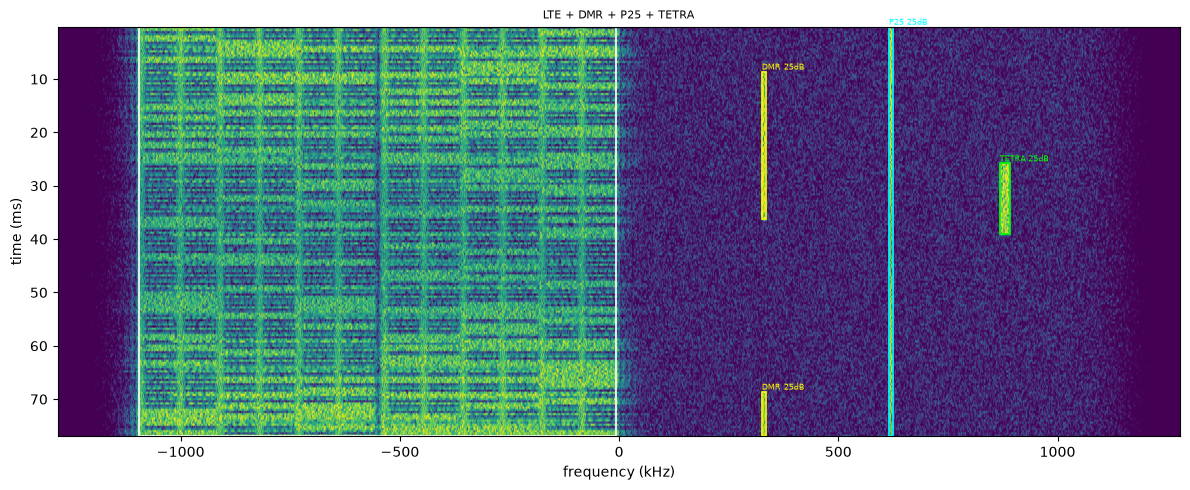

In [8]:
RF_CARRIERS = [390e6, 421.5e6, 451.0e6, 463.0e6, 751.0e6, 806.0e6]   # TETRA 380-430, DMR/P25 UHF 450-470, LTE band 28 / 800 (metadata; baseband is identical)


# optional extra for the TRAIN set only (default off, so existing datasets stay reproducible):
#   SPECTRUM_TRAIN_MID_FRAC  fraction of capture sessions with harder receiver impairments ("mid": between train and test_robust)
TRAIN_MID_FRAC = float(os.environ.get("SPECTRUM_TRAIN_MID_FRAC", "0"))


def session_for_group(set_id, group, profile):
    r = np.random.default_rng(np.random.SeedSequence([CFG.base_seed, set_id, group, 777]))
    rf = float(r.choice(RF_CARRIERS))
    if profile == "train":
        ppm, bits = float(r.choice([0.1, 2.0], p=[0.4, 0.6])), int(r.choice([12, 14], p=[0.6, 0.4]))
        irr, dc, fad = float(r.uniform(30, 50)), float(r.uniform(0.0, 0.2)), int(r.choice([0, 1, 2], p=[0.5, 0.3, 0.2]))
    elif profile == "mid":                                  # harder than train, still milder than test_robust (no Rayleigh fading, 10 bit ADC)
        ppm, bits = 5.0, 10
        irr, dc, fad = float(r.uniform(25, 40)), float(r.uniform(0.1, 0.35)), int(r.choice([1, 2]))
    else:
        ppm, bits = 10.0, 8
        irr, dc, fad = float(r.uniform(20, 30)), float(r.uniform(0.2, 0.5)), 3
    return dict(rf_hz=rf, ppm=ppm, cfo_hz=float(r.uniform(-ppm, ppm) * 1e-6 * rf), adc_bits=bits, irr_db=irr,
                dc_rel=dc, fading_level=fad, kappa_phase=float(r.uniform(0, 2 * np.pi)), dc_phase=float(r.uniform(0, 2 * np.pi)))


def make_specs(set_name, start=0, stop=None):
    n_total, sid = SET_SIZES[set_name], SET_IDS[set_name]
    stop = n_total if stop is None else min(stop, n_total)
    mode = SET_MODE.get(set_name, "general")
    profile = "hard" if set_name == "test_robust" else "train"
    sessions, specs = {}, []
    for i in range(start, stop):
        g = i // CFG.group_size
        if g not in sessions:
            prof = profile
            if set_name == "train" and TRAIN_MID_FRAC > 0 and np.random.default_rng(np.random.SeedSequence([CFG.base_seed, sid, g, 555])).random() < TRAIN_MID_FRAC:
                prof = "mid"
            sessions[g] = session_for_group(sid, g, prof)
        seed = int(np.random.SeedSequence([CFG.base_seed, sid, i]).generate_state(1, np.uint64)[0])
        scene_mode = mode
        specs.append(dict(set=set_name, scene_id=f"{set_name}_{i:07d}", index=i, group_id=f"{set_name}_g{g:05d}",
                          seed=seed, mode=scene_mode, session=sessions[g]))
    return specs


# one scene per protocol for a first look: spectrogram with the automatic boxes drawn on top
FAM_COLORS = {1: "white", 2: "yellow", 3: "cyan", 4: "lime", 5: "red"}        # LTE, DMR, P25, TETRA, unknown


def plot_scene(sc, ax=None, title=None, xlim=None):
    ax = ax or plt.gca()
    db = dequantize_db(sc["spec"])
    ext = [(-CFG.n_fft / 2 - 0.5) * DF / 1e3, (CFG.n_fft / 2 - 0.5) * DF / 1e3,
           ((CFG.n_frames - 1) * CFG.hop + CFG.n_fft / 2 + CFG.hop / 2) / FS * 1e3, (CFG.n_fft / 2 - CFG.hop / 2) / FS * 1e3]
    ax.imshow(db, aspect="auto", extent=ext, cmap="viridis", vmin=-5, vmax=30)
    for r in sc["signals"]:
        f0 = (r["box_x0"] - CFG.n_fft / 2 - 0.5) * DF / 1e3
        f1 = (r["box_x1"] - CFG.n_fft / 2 + 0.5) * DF / 1e3
        t0 = (r["box_y0"] * CFG.hop + CFG.n_fft / 2 - CFG.hop / 2) / FS * 1e3
        t1 = (r["box_y1"] * CFG.hop + CFG.n_fft / 2 + CFG.hop / 2) / FS * 1e3
        ax.add_patch(Rectangle((f0, t0), f1 - f0, t1 - t0, fill=False, ec=FAM_COLORS[r["family_id"]], lw=1.2))
        ax.text(f0, t0, f'{r["class_name"]} {r["snr_db"]:.0f}dB', color=FAM_COLORS[r["family_id"]], fontsize=6, va="bottom")
    if xlim is not None:
        ax.set_xlim(*xlim)
    ax.set_xlabel("frequency (kHz)")
    ax.set_ylabel("time (ms)")
    ax.set_title(title or sc["scene"]["scene_id"], fontsize=8)


_demo = make_specs("train", 0, 1)[0]
_demo["force"] = [dict(cls="LTE", snr_db=18, fc_hz=-550e3), dict(cls="DMR", snr_db=25, fc_hz=330e3),
                  dict(cls="P25", snr_db=25, fc_hz=620e3), dict(cls="TETRA", snr_db=25, fc_hz=880e3)]
_t0 = time.time()
_sc = make_scene(_demo)
print(f"one scene: {(time.time() - _t0) * 1e3:.0f} ms, spectrogram {_sc['spec'].shape} uint8, IQ {_sc['iq'].shape} int16")
plt.figure(figsize=(12, 5))
plot_scene(_sc, title="LTE + DMR + P25 + TETRA")
plt.tight_layout()
plt.show()

## 8. Simulator validation (before generating any data)

Checks against theory and against the protocol standards:

1. **Noise floor:** unit-variance complex noise must sit at 0 dB in the spectrogram.
2. **SNR convention:** the measured in-band SNR of a scaled signal must match the requested SNR, for every protocol.
3. **Occupied bandwidth:** LTE about 1.1 MHz, DMR / P25 under 12.5 kHz, TETRA under 25 kHz.
4. **Deviation:** the 4FSK outer tones of DMR (+-1944 Hz) and P25 (+-1800 Hz).
5. **Timing:** DMR mobile bursts 27.5 ms every 60 ms, TETRA slots 14.167 ms every 56.67 ms, LTE symbol-power periodicity 1 ms.

In [9]:
rng = np.random.default_rng(0)

# 1) noise floor
mp_ = np.mean([spectrogram_pow(((rng.standard_normal(NS) + 1j * rng.standard_normal(NS)) / np.sqrt(2)).astype(np.complex64)).mean() for _ in range(20)])
print(f"1) noise floor: mean power = {10 * np.log10(mp_):+.3f} dB (expected 0 dB)")
assert abs(10 * np.log10(mp_)) < 0.1

# 2) SNR convention, every protocol (noise estimated in an empty region beyond +-0.7 MHz, scaled to the reference bandwidth)
def measured_snr_db(cls, target_db, trials=12):
    vals = []
    f = np.fft.fftfreq(NS, 1 / FS)
    for _ in range(trials):
        x, _ = gen_signal(rng, cls, NS)
        lo, hi = obw_bounds(x)
        obw = hi - lo
        p_on = float(np.mean(np.abs(x) ** 2))
        amp, b_ref = snr_amplitude(obw, p_on, target_db)
        rx = amp * x + (rng.standard_normal(NS) + 1j * rng.standard_normal(NS)) / np.sqrt(2)
        P = np.abs(np.fft.fft(rx)) ** 2 / NS ** 2
        band = np.abs(f) <= b_ref / 2
        noise = P[np.abs(f) > 0.7e6].mean() * band.sum()
        vals.append(10 * np.log10(max(P[band].sum() - noise, 1e-12) / noise))
    return float(np.mean(vals))

for cls in KNOWN:
    m = measured_snr_db(cls, 15.0)
    print(f"2) {cls:6s} target 15.0 dB -> measured {m:5.2f} dB")
    assert abs(m - 15.0) < 1.0, cls

# 3) occupied bandwidth (99% power, continuous signal)
obw_tab = {}
for cls in KNOWN + UNKNOWN:
    ws = []
    for _ in range(6):
        x, _ = gen_signal(rng, cls, NS)
        lo, hi = obw_bounds(x)
        ws.append(hi - lo)
    obw_tab[cls] = (np.min(ws), np.median(ws), np.max(ws))
print("3) 99% occupied bandwidth (kHz): min / median / max")
display(pd.DataFrame({k: np.array(v) / 1e3 for k, v in obw_tab.items()}, index=["min", "median", "max"]).round(2))
assert 1.0e6 < obw_tab["LTE"][1] < 1.15e6
assert 5e3 < obw_tab["DMR"][1] < 12.5e3 and 5e3 < obw_tab["P25"][1] < 12.5e3
assert 18e3 < obw_tab["TETRA"][1] < 25e3

# 4) 4FSK levels of DMR and P25: sample the instantaneous frequency at the symbol centers (best of all timing offsets)
def level_error(cls):
    x, info = gen_signal(rng, cls, NS)
    u = info["dev_unit_hz"]
    inst = np.angle(x[1:] * np.conj(x[:-1])) * FS / (2 * np.pi)
    inst = np.convolve(inst, np.ones(40) / 40, mode="same")
    sps = FS / 4800.0
    best = (9e9, 0)
    for off in range(0, int(sps), 4):
        idx = np.round(off + 20000 + np.arange(200) * sps).astype(int)
        v = np.abs(inst[idx])
        err = np.minimum(np.abs(v - u), np.abs(v - 3 * u)).mean() / u
        best = min(best, (err, off))
    return best[0], u
for cls, nominal in (("DMR", 648.0), ("P25", 600.0)):
    err, u = level_error(cls)
    print(f"4) {cls}: symbol levels sit within {err * 100:.1f}% of +-{u:.0f} / +-{3 * u:.0f} Hz (standard unit {nominal:.0f} Hz)")
    assert err < 0.12

# 5) timing from plan_activity, on a 0.5 s plan (a 77 ms scene holds at most one full 60 ms DMR frame)
r5 = np.random.default_rng(5)
n_long = int(0.5 * FS)
checks = {}
for name, key, full_ms in (("DMR", "dmr_mode", 27.5), ("TETRA", "tetra_mode", 0.93 * 14.167)):
    for _ in range(5000):
        env_i, lab_i, ainfo = plan_activity(r5, name, n_long, FS)
        full = [(a, b) for a, b in env_i if abs((b - a) / FS * 1e3 - full_ms) < 0.05]
        if ainfo.get(key) == "uplink_1slot" and len(full) >= 3:
            checks[name] = (np.diff([a for a, _ in full[:3]]).mean() / FS * 1e3, (full[0][1] - full[0][0]) / FS * 1e3)
            break
print(f"5) DMR uplink 1 slot  : period {checks['DMR'][0]:.2f} ms (expect 60), burst {checks['DMR'][1]:.2f} ms (expect 27.5)")
print(f"   TETRA uplink 1 slot: period {checks['TETRA'][0]:.2f} ms (expect 56.67), burst {checks['TETRA'][1]:.2f} ms (expect 13.18)")
assert abs(checks["DMR"][0] - 60) < 0.1 and abs(checks["DMR"][1] - 27.5) < 0.1
assert abs(checks["TETRA"][0] - 56.668) < 0.1 and abs(checks["TETRA"][1] - 0.93 * 14.167) < 0.1

# LTE: symbol-power periodicity (PDCCH symbols are the strongest: one burst of them every 1 ms subframe)
x_lte = None
for _ in range(60):
    x, info = gen_signal(rng, "LTE", NS)
    if info["duplex"] == "FDD" and info["load"] < 0.5:
        x_lte = x
        break
assert x_lte is not None
sym = np.abs(x_lte[:2560 * 60]) ** 2
sym = sym[:len(sym) // 183 * 183].reshape(-1, 183).mean(1)               # about one OFDM symbol (71.4 us = 183 samples at 2.56 MS/s)
ac = np.correlate(sym - sym.mean(), sym - sym.mean(), "full")[len(sym) - 1:]
lag_ms = (np.argmax(ac[8:30]) + 8) * 183 / FS * 1e3
print(f"   LTE: strongest symbol-power periodicity at {lag_ms:.2f} ms (expect 1 ms = 14 symbols)")
assert 0.9 < lag_ms < 1.1
print("simulator validation passed")

1) noise floor: mean power = -0.003 dB (expected 0 dB)
2) LTE    target 15.0 dB -> measured 15.00 dB
2) DMR    target 15.0 dB -> measured 14.99 dB
2) P25    target 15.0 dB -> measured 15.00 dB
2) TETRA  target 15.0 dB -> measured 15.00 dB
3) 99% occupied bandwidth (kHz): min / median / max


,LTE,DMR,P25,TETRA,NBFM,WFM,GSM
min,1080.20,7.52,6.80,20.79,4.86,65.21,247.76
median,1085.03,7.89,7.10,20.97,5.34,73.72,248.56
max,1086.75,8.19,7.52,21.17,8.26,92.91,249.04


4) DMR: symbol levels sit within 6.4% of +-646 / +-1939 Hz (standard unit 648 Hz)
4) P25: symbol levels sit within 6.5% of +-573 / +-1718 Hz (standard unit 600 Hz)
5) DMR uplink 1 slot  : period 59.98 ms (expect 60), burst 27.45 ms (expect 27.5)
   TETRA uplink 1 slot: period 56.67 ms (expect 56.67), burst 13.18 ms (expect 13.18)
   LTE: strongest symbol-power periodicity at 1.00 ms (expect 1 ms = 14 symbols)
simulator validation passed


## 9. Build engine

Scenes are generated in parallel (one shard of 250 scenes per task) and written as:

| File | Content |
|---|---|
| `shard_XXXX_spec.npy` | `uint8 [scene, 128, 1024]` dB relative to the noise floor (memory-mappable) |
| `shard_XXXX_iq.npy` | `int16 [scene, 33536, 2]` raw IQ (left-aligned ADC codes; scale in `scenes` table) |
| `shard_XXXX_mask.npz` | `uint8 [scene, 128, 1024]` family-id pixel mask (0 = background), compressed |
| `scenes.*`, `signals.*` | one row per scene / per labeled box (Parquet if `pyarrow` is installed, else CSV.gz) |
| `coco.json` | detection boxes: `bbox = [x = frequency bin, y = time frame, width, height]`, category = family id |
| `_SUCCESS` | manifest with SHA-256 checksums |

A finished set is **not regenerated** unless you ask for it (`SPECTRUM_REBUILD=name`); frozen test sets also need `SPECTRUM_FORCE_FROZEN=1`.

In [12]:
import shutil


def save_table(df, base):
    base = str(base)
    try:
        df.to_parquet(base + ".parquet", index=False)
        return base + ".parquet"
    except Exception:
        if os.path.exists(base + ".parquet"):
            os.remove(base + ".parquet")
        df.to_csv(base + ".csv.gz", index=False)
        return base + ".csv.gz"


def load_table(base):
    base = str(base)
    if os.path.exists(base + ".parquet"):
        return pd.read_parquet(base + ".parquet")
    return pd.read_csv(base + ".csv.gz")


def sha256_file(path, chunk=1 << 24):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        while True:
            b = f.read(chunk)
            if not b:
                break
            h.update(b)
    return h.hexdigest()


def build_shard(job):
    set_name, shard_idx, specs, set_dir = job
    n = len(specs)
    spec_arr = np.empty((n, CFG.n_frames, CFG.n_fft), np.uint8)
    mask_arr = np.empty_like(spec_arr)
    iq_arr = np.empty((n, NS, 2), np.int16) if STORE_IQ else None
    scene_rows, sig_rows = [], []
    for j, sp in enumerate(specs):
        out = make_scene(sp)
        spec_arr[j], mask_arr[j] = out["spec"], out["mask"]
        if STORE_IQ:
            iq_arr[j] = out["iq"]
        out["scene"].update(shard=shard_idx, pos=j)
        scene_rows.append(out["scene"])
        for r in out["signals"]:
            r.update(shard=shard_idx, pos=j)
            sig_rows.append(r)
    base = f"{set_dir}/shard_{shard_idx:04d}"
    np.save(base + "_spec.npy", spec_arr)
    if STORE_IQ:
        np.save(base + "_iq.npy", iq_arr)
    np.savez_compressed(base + "_mask.npz", mask=mask_arr)
    return shard_idx, scene_rows, sig_rows


def write_coco(set_dir, scenes, signals):
    images = [dict(id=int(r.index), file_name=f"shard_{int(r.shard):04d}_spec.npy#{int(r.pos)}", width=CFG.n_fft,
                   height=CFG.n_frames, scene_id=r.scene_id) for r in scenes.itertuples()]
    idx_of = dict(zip(scenes.scene_id, scenes["index"]))
    anns = []
    for k, r in enumerate(signals.itertuples()):
        w, h = r.box_x1 - r.box_x0 + 1, r.box_y1 - r.box_y0 + 1
        anns.append(dict(id=k, image_id=int(idx_of[r.scene_id]), category_id=int(r.family_id), bbox=[int(r.box_x0), int(r.box_y0), int(w), int(h)],
                         area=int(w * h), iscrowd=0, class_name=r.class_name, snr_db=float(r.snr_db), burst_type=r.burst_type))
    cats = [dict(id=v, name=k) for k, v in FAMILY_ID.items()]
    with open(f"{set_dir}/coco.json", "w") as f:
        json.dump(dict(images=images, annotations=anns, categories=cats,
                       info=dict(description="x = frequency bin (0 = -fs/2), y = time frame", version=CFG.version)), f)


def run_set(set_name):
    set_dir = OUT_DIR / "sets" / set_name
    if (set_dir / "_SUCCESS").exists():
        if set_name not in REBUILD:
            print(f"[skip] {set_name}: already built")
            return json.loads((set_dir / "_SUCCESS").read_text())
        if set_name in FROZEN_SETS and not FORCE_FROZEN:
            raise RuntimeError(f"{set_name} is a frozen test set; set SPECTRUM_FORCE_FROZEN=1 to regenerate it")
    if set_dir.exists():
        shutil.rmtree(set_dir)                      # rebuild, or leftovers of an interrupted run
    set_dir.mkdir(parents=True)
    t0 = time.time()
    specs = make_specs(set_name)
    jobs = [(set_name, k, specs[i:i + CFG.shard_size], str(set_dir)) for k, i in enumerate(range(0, len(specs), CFG.shard_size))]
    results = []
    if N_WORKERS > 1 and len(jobs) > 1 and "fork" in mp.get_all_start_methods():
        with mp.get_context("fork").Pool(min(N_WORKERS, len(jobs))) as pool:
            for r in tqdm(pool.imap_unordered(build_shard, jobs), total=len(jobs), desc=set_name):
                results.append(r)
    else:
        for job in tqdm(jobs, desc=set_name):
            results.append(build_shard(job))
    results.sort(key=lambda r: r[0])
    scenes = pd.DataFrame([row for _, sc, _ in results for row in sc])
    signals = pd.DataFrame([row for _, _, sg in results for row in sg])
    save_table(scenes, set_dir / "scenes")
    save_table(signals, set_dir / "signals")
    write_coco(set_dir, scenes, signals)
    files = sorted(p for p in set_dir.iterdir() if p.is_file())
    manifest = dict(set=set_name, version=CFG.version, profile=PROFILE, frozen=set_name in FROZEN_SETS, n_scenes=len(scenes),
                    n_boxes=len(signals), n_groups=int(scenes.group_id.nunique()), seconds=round(time.time() - t0, 1),
                    built_utc=datetime.datetime.now(datetime.timezone.utc).isoformat(timespec="seconds"),
                    checksums={p.name: sha256_file(p) for p in files},
                    bytes=int(sum(p.stat().st_size for p in files)))
    (set_dir / "_SUCCESS").write_text(json.dumps(manifest, indent=1))
    return manifest

## 10. Generate the dataset

Run time scales linearly with the number of scenes and (nearly) with the number of workers. Disk use is about 0.13 MB per scene for the spectrogram plus 0.13 MB for the raw IQ (if stored).

In [ ]:
OUT_DIR.mkdir(parents=True, exist_ok=True)
(OUT_DIR / "config.json").write_text(json.dumps(dict(
    config=asdict(CFG), profile=PROFILE, set_sizes=SET_SIZES, store_iq=STORE_IQ, db_step=DB_STEP,
    frozen_sets=sorted(FROZEN_SETS), classes=CLASS_TABLE + UNKNOWN_TABLE, family_id=FAMILY_ID, coarse_id=COARSE_ID,
    software=dict(python=platform.python_version(), numpy=np.__version__, scipy=scipy.__version__, pandas=pd.__version__),
    created_utc=datetime.datetime.now(datetime.timezone.utc).isoformat(timespec="seconds")), indent=1, default=str))

est_gb = sum(SET_SIZES.values()) * (CFG.n_frames * CFG.n_fft * 1.1 + (NS * 4 if STORE_IQ else 0)) / 1e9
print(f"about {est_gb:.1f} GB will be written to {OUT_DIR}")

t_all = time.time()
manifests = {name: run_set(name) for name in SET_SIZES}
print(f"\ntotal wall time {time.time() - t_all:.0f} s")
pd.DataFrame([dict(set=m["set"], scenes=m["n_scenes"], boxes=m["n_boxes"], groups=m["n_groups"], GB=round(m["bytes"] / 1e9, 2),
                   build_s=m["seconds"], frozen=m["frozen"]) for m in manifests.values()])

## 11. Quality assurance (R&D 3.4)

Automatic checks on the written data:

1. **Structure:** counts, box bounds, valid class ids, family consistency, SNR ranges per set, unknown classes only in `test_openset`, unique seeds, no group shared between sets.
2. **Label correctness:** for a sample of scenes the generator is re-run with `keep_components=True`, and the share of each signal's **noise-free** spectrogram energy that falls inside its labeled box is measured (independent of SNR).
3. **Determinism:** regenerated scenes must reproduce the stored spectrograms bit for bit.
4. **Visual inspection:** boxes drawn on random stored spectrograms.

In [ ]:
def read_tables(set_name):
    d = OUT_DIR / "sets" / set_name
    return load_table(d / "scenes"), load_table(d / "signals")


issues = []
all_scenes = []
box_cols = ["box_x0", "box_y0", "box_x1", "box_y1"]
for name in SET_SIZES:
    sc, sg = read_tables(name)
    all_scenes.append(sc)
    if len(sc) != SET_SIZES[name]:
        issues.append(f"{name}: {len(sc)} scenes, expected {SET_SIZES[name]}")
    if len(sg):
        if not ((sg.box_x0 >= 0) & (sg.box_x1 < CFG.n_fft) & (sg.box_x1 >= sg.box_x0) & (sg.box_y0 >= 0) & (sg.box_y1 < CFG.n_frames) & (sg.box_y1 > sg.box_y0)).all():
            issues.append(f"{name}: box outside the image or empty")
        if sg[box_cols + ["center_hz", "obw_hz", "snr_db", "t_start_s", "t_end_s"]].isna().any().any():
            issues.append(f"{name}: NaN in label columns")
        if not (sg.t_end_s > sg.t_start_s).all():
            issues.append(f"{name}: non-positive burst duration")
        fam_of = {n: FAMILY_ID[CLASS[n]["family"]] for n in CLASS}
        if not (sg.class_name.map(fam_of) == sg.family_id).all():
            issues.append(f"{name}: family id inconsistent with class")
        snr_ok = sg.snr_db.between(*CFG.snr_range) if name != "test_snr_stress" else ~sg.snr_db.between(*CFG.snr_range)
        if not snr_ok.all():
            issues.append(f"{name}: SNR outside the intended range")
        if name != "test_openset" and (sg.class_id >= len(CLASS_TABLE)).any():
            issues.append(f"{name}: held-out class present")
        if name == "test_openset" and not (sg.groupby("scene_id").class_id.max() >= len(CLASS_TABLE)).all():
            issues.append("test_openset: scene without a held-out class")
allsc = pd.concat(all_scenes)
if allsc.seed.duplicated().any():
    issues.append("duplicate seeds")
grp_sets = allsc.groupby("group_id").set.nunique()
if (grp_sets > 1).any():
    issues.append("a session group appears in more than one set (leakage)")
print("structural QA:", "OK" if not issues else issues)
assert not issues

In [ ]:
def energy_fraction_qa(set_name, n_scenes, seed=0):
    r = np.random.default_rng(seed)
    out = []
    for i in r.choice(SET_SIZES[set_name], min(n_scenes, SET_SIZES[set_name]), replace=False):
        sc = make_scene(make_specs(set_name, int(i), int(i) + 1)[0], keep_components=True)
        for k, comp in enumerate(sc["components"]):
            P = spectrogram_pow(comp)
            m = np.zeros(P.shape, bool)
            for row in sc["signals"]:
                if row["sig_idx"] == k:
                    m[row["box_y0"]:row["box_y1"] + 1, row["box_x0"]:row["box_x1"] + 1] = True
            first = next(rw for rw in sc["signals"] if rw["sig_idx"] == k)
            out.append(dict(set=set_name, scene_id=sc["scene"]["scene_id"], class_name=first["class_name"], burst_type=first["burst_type"],
                            snr_db=first["snr_db"], frac=float(P[m].sum() / P.sum())))
    return pd.DataFrame(out)


n_qa = 60 if PROFILE == "smoke" else 200
qa = pd.concat([energy_fraction_qa(s, n_qa) for s in ("train", "test_openset")])
summary = qa.groupby("burst_type").frac.describe(percentiles=[0.1, 0.5]).round(3)[["count", "10%", "50%", "min"]]
print("share of a signal's noise-free spectrogram energy inside its labeled box:")
display(summary)
display(qa.groupby("class_name").frac.median().round(3).to_frame("median").T)
assert qa.frac.median() > 0.90, "labels do not enclose the signal energy"
assert qa[qa.burst_type.isin(["continuous", "long"])].frac.median() > 0.93

determinism check: 0 of 20 regenerated scenes differ from the stored data


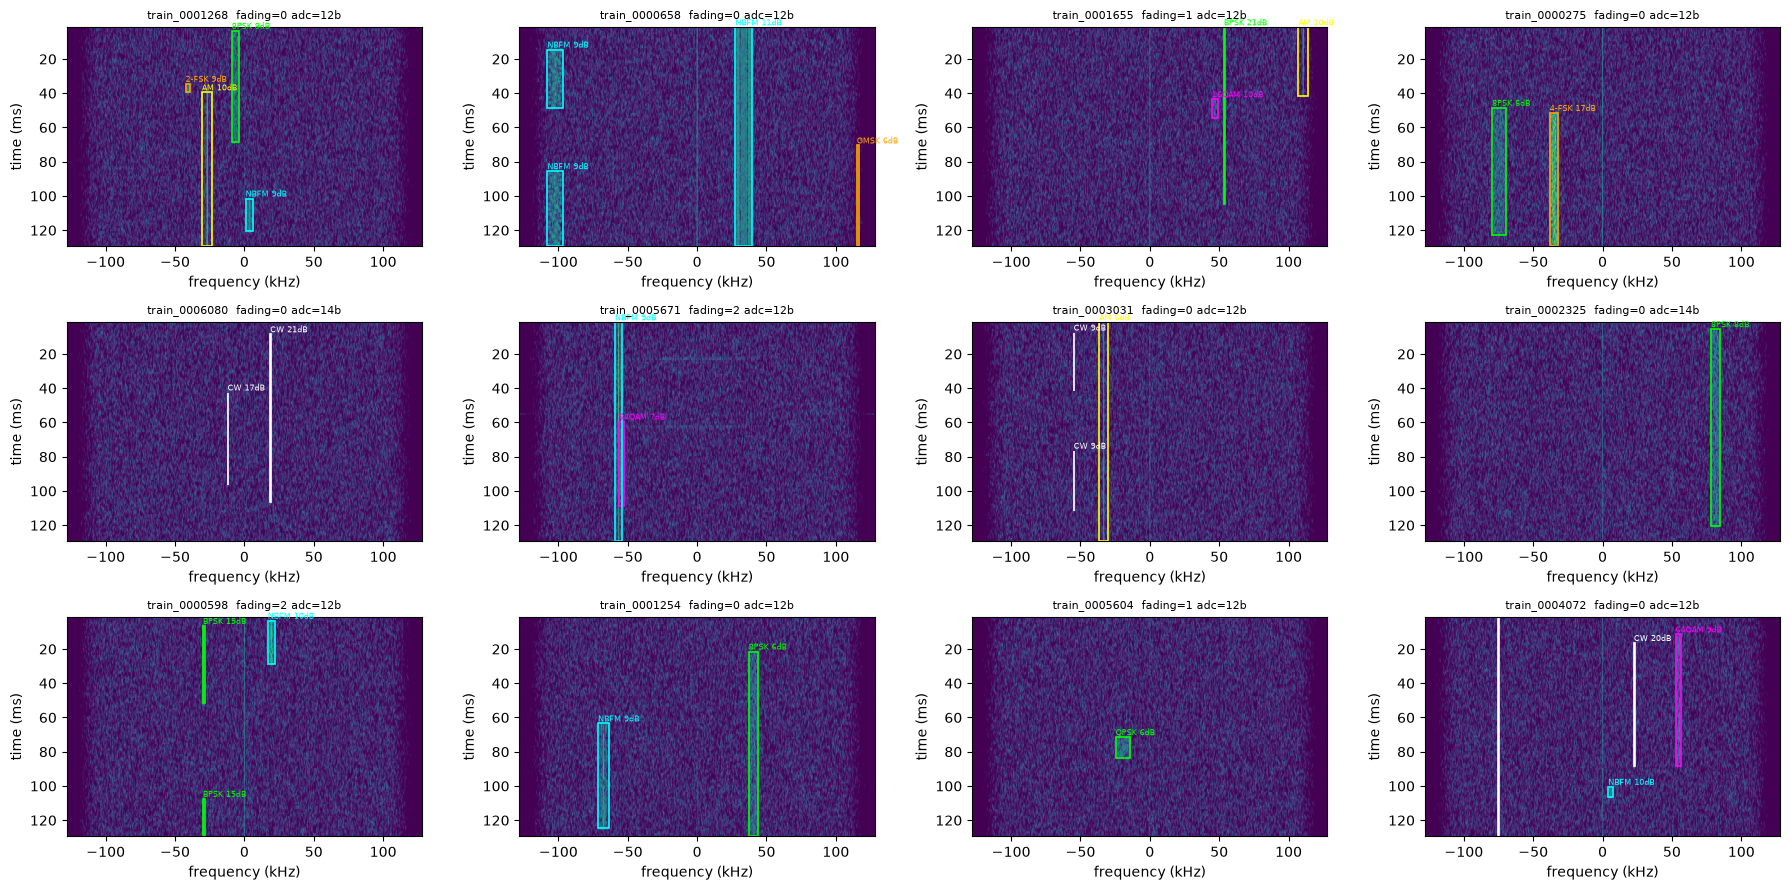

In [16]:
# determinism: regenerate scenes and compare with what is on disk
sc_tr, sg_tr = read_tables("train")
bad = 0
for i in np.random.default_rng(1).choice(len(sc_tr), min(20, len(sc_tr)), replace=False):
    row = sc_tr.iloc[int(i)]
    again = make_scene(make_specs("train", int(row["index"]), int(row["index"]) + 1)[0])
    stored = np.load(OUT_DIR / "sets" / "train" / f"shard_{int(row['shard']):04d}_spec.npy", mmap_mode="r")[int(row["pos"])]
    bad += int(not np.array_equal(again["spec"], stored) or again["scene"]["spec_sha1"] != row["spec_sha1"])
print(f"determinism check: {bad} of 20 regenerated scenes differ from the stored data")
assert bad == 0

# visual inspection of stored data (boxes come from the label tables, not from the generator)
def stored_scene(set_name, row, sg):
    spec = np.load(OUT_DIR / "sets" / set_name / f"shard_{int(row['shard']):04d}_spec.npy", mmap_mode="r")[int(row["pos"])]
    return dict(spec=np.asarray(spec), signals=sg[sg.scene_id == row["scene_id"]].to_dict("records"), scene=dict(scene_id=row["scene_id"]))

fig, axes = plt.subplots(3, 4, figsize=(18, 9))
pick = np.random.default_rng(3).choice(len(sc_tr), 12, replace=False)
for ax, i in zip(axes.ravel(), pick):
    r = sc_tr.iloc[int(i)]
    plot_scene(stored_scene("train", r, sg_tr), ax=ax, title=f'{r["scene_id"]}  fading={r["fading_level"]} adc={r["adc_bits"]}b')
plt.tight_layout()
fig.savefig(OUT_DIR / "qa_overlays_train.png", dpi=110)
plt.show()

In [ ]:
# one stored example per protocol, zoomed on the labeled signal
sc_z, sg_z = read_tables("train")
fig, axes = plt.subplots(1, len(KNOWN), figsize=(20, 4.5))
for ax, name in zip(axes, KNOWN):
    cand = sg_z[(sg_z.class_name == name) & (sg_z.snr_db > 18)]
    if len(cand) == 0:
        ax.set_title(f"{name}: none"); continue
    b = cand.iloc[0]
    r = sc_z[sc_z.scene_id == b.scene_id].iloc[0]
    half = max(40.0, 1.6 * b.obw_hz / 2e3)
    plot_scene(stored_scene("train", r, sg_z), ax=ax, title=f'{name}: {b.obw_hz / 1e3:.1f} kHz wide, {b.snr_db:.0f} dB (zoom)', xlim=(b.center_hz / 1e3 - half, b.center_hz / 1e3 + half))
plt.tight_layout()
plt.show()

## 12. Dataset statistics

In [ ]:
frames = {n: read_tables(n) for n in SET_SIZES}
overview = pd.DataFrame([dict(set=n, scenes=len(sc), boxes=len(sg), empty_scenes=int((sc.n_signals == 0).sum()),
                              with_interferer=int((sc.n_interferers > 0).sum()), groups=sc.group_id.nunique()) for n, (sc, sg) in frames.items()])
display(overview)

sg_all = pd.concat([sg for _, sg in frames.values()])
tr = frames["train"][1]
fig, ax = plt.subplots(2, 3, figsize=(18, 8))
tr.drop_duplicates(["scene_id", "sig_idx"]).family.value_counts().reindex(FAMILIES).plot.bar(ax=ax[0, 0], title="train: signals per protocol")
tr.drop_duplicates(["scene_id", "sig_idx"]).class_name.value_counts().reindex(KNOWN).plot.bar(ax=ax[0, 1], title="train: signals per protocol (fine class)")
tr.drop_duplicates(["scene_id", "sig_idx"]).snr_db.plot.hist(bins=25, ax=ax[0, 2], title="train: SNR (dB)")
tr.burst_type.value_counts().reindex(["continuous", "long", "short", "very_short", "train"]).dropna().plot.bar(ax=ax[1, 0], title="train: boxes per burst type")
tr.drop_duplicates(["scene_id", "sig_idx"]).boxplot(column="obw_hz", by="class_name", ax=ax[1, 1], rot=60)
ax[1, 1].set_title("train: 99%-power occupied bandwidth (Hz)"); ax[1, 1].set_yscale("log"); plt.sca(ax[1, 1]); plt.suptitle("")
frames["train"][0].n_signals.value_counts().sort_index().plot.bar(ax=ax[1, 2], title="train: signals per scene")
plt.tight_layout()
plt.show()

## 13. Datasheet, loader and optional YOLO export

`DATASHEET.md` documents what the data contains and its known limitations. `SpectrumSet` reads a set with memory-mapped shards, ready for a PyTorch `DataLoader` (wrap `__getitem__`).

In [ ]:
def build_datasheet():
    lines = [f"# Dataset datasheet: spectrum_rf v{CFG.version} ({PROFILE})", "",
             f"Generated {datetime.datetime.now(datetime.timezone.utc).isoformat(timespec='seconds')} UTC with seed {CFG.base_seed}.", "",
             "## Format", f"- Spectrogram `[time={CFG.n_frames}, freq={CFG.n_fft}]`, uint8 dB relative to the noise floor: `db = q * {DB_STEP:.5f} + {CFG.db_min}`.",
             f"- fs = {CFG.fs:.0f} S/s complex, N_fft = {CFG.n_fft} ({DF:.0f} Hz bins), hop = {CFG.hop} ({CFG.hop / FS * 1e3:.2f} ms), Hann window, bins ascending from -fs/2.",
             f"- Scene = {NS} samples ({NS / FS * 1e3:.1f} ms). Raw IQ stored: {STORE_IQ}.", "",
             "## Sets", "| set | scenes | boxes | frozen |", "|---|---|---|---|"]
    for n, (sc, sg) in frames.items():
        lines.append(f"| {n} | {len(sc)} | {len(sg)} | {n in FROZEN_SETS} |")
    lines += ["", "## Labels (generated, not annotated)",
              "- Box frequency = the bounds holding 99% of the noise-free signal power, minimum one bin (1250 Hz).",
              "- Box time = frames whose window center lies inside a label interval, minimum two frames. Bursts closer than 5 ms are one transmission (one box); isolated TDMA bursts (DMR / TETRA mobiles) are separate boxes.",
              "- Classes (= protocols): " + ", ".join(KNOWN) + ". Held out (test_openset only): " + ", ".join(UNKNOWN) + ".",
              "- SNR = in-band SNR over the occupied bandwidth (reference bandwidth at least 500 Hz), nominal (before fading). Equal SNR means very different per-bin levels: LTE is about 860 bins wide, DMR / P25 about 6.",
              f"- SNR sampling: `train` is skewed towards the 5 dB floor (truncated exponential, tau = {CFG.snr_tau_train} dB); `val` and all test sets are uniform in {CFG.snr_range[0]:.0f} to {CFG.snr_range[1]:.0f} dB.",
              "", "## Known limitations",
              "- Synthetic data: validate on real captures (USRP / RTL-SDR / HackRF recordings of the four protocols) before trusting absolute numbers.",
              "- LTE: downlink only, 1.4 MHz carrier only (wider carriers do not fit in 2.56 MHz); resource allocation, PDCCH and reference signals are modeled, the data are random (no channel coding or scrambling).",
              "- DMR / P25 / TETRA: correct modulation, symbol rate, pulse shaping, slot timing and (DMR, P25) sync words; payload is random (no FEC, interleaving or voice codec), TETRA training sequences are not inserted.",
              "- DMR downlink and P25 are both continuous 4800-baud 4-level FSK in a 12.5 kHz channel. At 1250 Hz bins they are almost identical in a spectrogram; expect most confusion between these two.",
              "- Flat (narrowband) fading only; no multipath delay spread for LTE; no co-channel emitters outside the labeled signals.",
              "- Signals never overlap in frequency in a scene (15 kHz minimum gap); real channels can be adjacent or co-channel.",
              "- Box and mask are rectangles; the mask keeps the last signal's protocol id.",
              "- Spurs and impulses are present as unlabeled hard negatives (see `interferers_json`)."]
    (OUT_DIR / "DATASHEET.md").write_text("\n".join(lines) + "\n")


build_datasheet()


class SpectrumSet:
    # memory-mapped reader: set[i] -> dict(spec_db float32 [T,F], mask uint8 [T,F], iq complex64 or None, boxes DataFrame)
    def __init__(self, set_name, root=OUT_DIR):
        self.dir = Path(root) / "sets" / set_name
        self.scenes, self.signals = load_table(self.dir / "scenes"), load_table(self.dir / "signals")
        self.boxes = {k: g for k, g in self.signals.groupby("scene_id")}
        self._cache = {}

    def __len__(self):
        return len(self.scenes)

    def _shard(self, kind, k):
        key = (kind, k)
        if key not in self._cache:
            p = self.dir / f"shard_{k:04d}_{kind}"
            self._cache[key] = np.load(f"{p}.npz")["mask"] if kind == "mask" else np.load(f"{p}.npy", mmap_mode="r")
        return self._cache[key]

    def __getitem__(self, i):
        r = self.scenes.iloc[i]
        k, pos = int(r["shard"]), int(r["pos"])
        iq = None
        if (self.dir / f"shard_{k:04d}_iq.npy").exists():
            iq = iq_to_complex(np.asarray(self._shard("iq", k)[pos]), r["iq_scale"])
        return dict(spec_db=dequantize_db(np.asarray(self._shard("spec", k)[pos])), mask=np.asarray(self._shard("mask", k)[pos]), iq=iq,
                    boxes=self.boxes.get(r["scene_id"], self.signals.iloc[0:0]), scene=r)


ds = SpectrumSet("test")
item = ds[0]
print(len(ds), "scenes | spec", item["spec_db"].shape, "| mask classes", np.unique(item["mask"]), "| iq", None if item["iq"] is None else item["iq"].shape)
display(item["boxes"][["class_name", "family", "center_hz", "obw_hz", "snr_db", "burst_type", "box_x0", "box_x1", "box_y0", "box_y1"]])

In [ ]:
# Optional: export one set in YOLO format (PNG images + txt labels). Set EXPORT_YOLO=1 in the environment to enable.
EXPORT_YOLO = os.environ.get("EXPORT_YOLO", "0") == "1"


def export_yolo(set_name, limit=None):
    from PIL import Image
    ds_ = SpectrumSet(set_name)
    out = OUT_DIR / "yolo" / set_name
    (out / "images").mkdir(parents=True, exist_ok=True)
    (out / "labels").mkdir(parents=True, exist_ok=True)
    for i in tqdm(range(len(ds_) if limit is None else min(limit, len(ds_))), desc=f"yolo {set_name}"):
        it = ds_[i]
        img = np.clip((it["spec_db"] + 10) / 50 * 255, 0, 255).astype(np.uint8)          # -10..40 dB -> 0..255
        sid = it["scene"]["scene_id"]
        Image.fromarray(img).save(out / "images" / f"{sid}.png")
        W, H = CFG.n_fft, CFG.n_frames
        with open(out / "labels" / f"{sid}.txt", "w") as f:
            for b in it["boxes"].itertuples():
                if b.family_id > len(FAMILIES):
                    continue                                                           # held-out classes have no training label
                w, h = b.box_x1 - b.box_x0 + 1, b.box_y1 - b.box_y0 + 1
                f.write(f"{b.family_id - 1} {(b.box_x0 + w / 2) / W:.6f} {(b.box_y0 + h / 2) / H:.6f} {w / W:.6f} {h / H:.6f}\n")
    (out.parent / "dataset.yaml").write_text(f"path: {out.parent}\ntrain: train/images\nval: val/images\ntest: test/images\n"
                                             "names:\n" + "".join(f"  {i}: {f}\n" for i, f in enumerate(FAMILIES)))


if EXPORT_YOLO:
    for s in ("train", "val", "test"):
        export_yolo(s)
else:
    print("YOLO export skipped (set EXPORT_YOLO=1 to enable)")

In [21]:
EXPORT_YOLO

True

## 14. What is in the output folder and next steps

```
dataset/spectrum_rf_v<version>_<profile>/
  config.json, DATASHEET.md, qa_overlays_train.png
  sets/<set>/ shard_XXXX_{spec,iq}.npy  shard_XXXX_mask.npz  scenes.*  signals.*  coco.json  _SUCCESS
```

Next steps:

1. Train the detector (`train_detector.py`, 4 protocol classes, or `--single-class` plus `train_classifier.py` for a two-stage system) and the baselines on `train` / `val`; report on the frozen sets.
2. Check the confusion matrix, expecting most errors between DMR and P25.
3. Capture real LTE / DMR / P25 / TETRA recordings and measure the sim-to-real gap.
4. Scale with `SPECTRUM_PROFILE=main` once the labels and the receiver model look right.

## 15. Ten random spectrograms from the dataset, explained

This section draws **10 random scenes** from a stored set (default `train`, scenes with at least one labeled signal) and explains every feature visible in them. Set `SPECTRUM_SHOW_SEED` for another draw, or `SPECTRUM_SHOW_SET` to look at another set (for example `test_openset`).

**How to read one spectrogram**

| Element | Meaning |
|---|---|
| Horizontal axis | frequency, -1.28 to +1.28 MHz around the receiver center (2048 bins of 1250 Hz) |
| Vertical axis | time, 0 to about 77 ms (192 frames, 0.4 ms apart), time runs downward |
| Color | power in dB **relative to the noise floor** (0 dB = pure noise); dark = noise only, bright = signal |
| Colored rectangle | the automatic label of one transmission: frequency bounds holding 99% of the signal power x the frames in which it is on |
| Box color | protocol: white LTE, yellow DMR, cyan P25, lime TETRA, red unknown (open-set only) |
| Text on a box | protocol and nominal in-band SNR |

**Receiver effects to look for:** a thin bright line at 0 kHz (DC offset), a darker fall-off towards both band edges (anti-alias filter roll-off), thin unlabeled lines (spurs) and short vertical stripes (impulses) that act as hard negatives, and signals shifted by a few hundred Hz (oscillator error in ppm).

In [ ]:
from matplotlib.patches import Patch
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize
from IPython.display import Markdown, display

SHOW_SET = os.environ.get("SPECTRUM_SHOW_SET", "train")
SHOW_SEED = int(os.environ.get("SPECTRUM_SHOW_SEED", "2026"))      # change for another random draw
N_SHOW = 10
FADING_TXT = {0: "none (static channel)", 1: "Rician K=10 dB (mild fading)", 2: "Rician K=3 dB (strong fading)", 3: "Rayleigh (no line of sight)"}

show_ds = SpectrumSet(SHOW_SET)
candidates = np.flatnonzero(show_ds.scenes["n_boxes"].to_numpy() > 0)      # skip noise-only scenes
show_idx = np.sort(np.random.default_rng(SHOW_SEED).choice(candidates, N_SHOW, replace=False))

fig, axes = plt.subplots(2, 5, figsize=(30, 11), sharex=True, sharey=True)
for k, (ax, i) in enumerate(zip(axes.ravel(), show_idx), 1):
    r = show_ds.scenes.iloc[int(i)]
    plot_scene(stored_scene(SHOW_SET, r, show_ds.signals), ax=ax,
               title=f'({k}) {r["scene_id"]}\n{int(r["n_signals"])} signal(s) | ADC {int(r["adc_bits"])} bit | fading: {FADING_TXT[int(r["fading_level"])].split(" (")[0]}')
fig.suptitle(f"{N_SHOW} random spectrograms from '{SHOW_SET}' (seed {SHOW_SEED}): frequency x time, dB above the noise floor, boxes = automatic labels", fontsize=15)
fig.tight_layout(rect=[0, 0.05, 0.92, 0.95])
cax = fig.add_axes([0.935, 0.15, 0.01, 0.7])
fig.colorbar(ScalarMappable(norm=Normalize(-5, 30), cmap="viridis"), cax=cax, label="dB relative to the noise floor")
handles = [Patch(fill=False, ec=FAM_COLORS[FAMILY_ID[f]], lw=2, label=f) for f in FAMILIES] + [Patch(fill=False, ec=FAM_COLORS[UNKNOWN_ID], lw=2, label="unknown (open-set)")]
fig.legend(handles=handles, loc="lower center", ncol=len(handles), facecolor="#222222", labelcolor="white", fontsize=12)
fig.savefig(OUT_DIR / "section15_random_spectrograms.png", dpi=130)
plt.show()

In [ ]:
WHAT_YOU_SEE = {
    "LTE": "a wide block about 1.1 MHz across (about 860 bins), striped in time: every 1 ms subframe starts with 1 to 3 bright full-band PDCCH symbols, followed by data on a changing share of the 6 resource blocks; thin vertical lines every 6th subcarrier are reference signals. A TDD cell has silent uplink subframes.",
    "DMR": "a very narrow vertical line (about 6 bins, 7 to 8 kHz). A repeater downlink is continuous; a mobile is a series of 27.5 ms bursts every 60 ms (one slot) or back-to-back bursts with 2.5 ms gaps (both slots, drawn as one box).",
    "P25": "a very narrow vertical line (about 6 bins, 7 to 8 kHz), continuous for the whole transmission. Looks like a DMR downlink; the difference is in the timing (no TDMA bursts) and in the sub-bin spectral details.",
    "TETRA": "a narrow band about 20 bins (about 25 kHz) wide, 3 times wider than DMR / P25. Base station main carrier is continuous; traffic carriers and mobiles appear as 14 ms slot bursts repeating every 56.7 ms.",
    "NBFM": "(held out) a narrow wavering line (analog voice FM, about 6 to 13 kHz) with a continuously varying width; no TDMA structure. Designed to be confused with DMR / P25.",
    "WFM": "(held out) a 100 to 200 kHz wide band that wanders with the audio.",
    "GSM": "(held out) a 200 kHz wide bell-shaped band with the 577 us slot structure of 8-slot TDMA.",
}
BURST_TXT = {"continuous": "continuous (on the whole scene)", "long": "long burst", "short": "short burst", "very_short": "very short burst (stress case)", "train": "burst train (repeated on/off keying)",
            }


def fmt_params(p):
    d = json.loads(p) if isinstance(p, str) else {}
    return ", ".join(f"{k}={v:.4g}" if isinstance(v, (int, float)) else f"{k}={v}" for k, v in d.items()) or "none"


def fmt_interferers(s):
    out = []
    for d in (json.loads(s) if isinstance(s, str) else []):
        if d.get("kind") == "spur":
            out.append(f"spur at {d['center_hz'] / 1e3:+.1f} kHz ({d['snr_db']:.1f} dB, a thin unlabeled line)")
        else:
            out.append(f"{d.get('kind', 'interferer')} (a short unlabeled vertical stripe)")
    return ", ".join(out) or "none"


summary = []
for k, i in enumerate(show_idx, 1):
    r = show_ds.scenes.iloc[int(i)]
    sg = show_ds.boxes.get(r["scene_id"], show_ds.signals.iloc[0:0])
    db = dequantize_db(stored_scene(SHOW_SET, r, show_ds.signals)["spec"])
    floor = float(np.median(db))
    lines = [f"### ({k}) `{r['scene_id']}`",
             f"**Receiver and session:** RF carrier {r['rf_hz'] / 1e6:.3f} MHz, oscillator error {r['ppm']:g} ppm (common frequency shift {r['cfo_hz']:+.0f} Hz), "
             f"ADC {int(r['adc_bits'])} bit, IQ image rejection {r['irr_db']:.1f} dB, DC offset {r['dc_rel']:.3f} (relative), fading: {FADING_TXT[int(r['fading_level'])]}.",
             f"**Scene:** mode `{r['mode']}`, {int(r['n_signals'])} labeled signal(s) in {len(sg)} box(es); noise floor of the image (median) = {floor:+.1f} dB; "
             f"unlabeled hard negatives: {fmt_interferers(r['interferers_json'])}.",
             "**Labeled signals:**"]
    for b in sg.itertuples():
        reg = db[b.box_y0:b.box_y1 + 1, b.box_x0:b.box_x1 + 1]
        burst = f" (burst {int(b.burst_idx) + 1})" if b.burst_type == "train" else ""
        lines.append(
            f"- **{b.class_name}**{burst}: family `{b.family}`, coarse group `{b.coarse}`; center {b.center_hz / 1e3:+.2f} kHz, occupied bandwidth {b.obw_hz / 1e3:.2f} kHz "
            f"(box {b.box_x1 - b.box_x0 + 1} bins x {b.box_y1 - b.box_y0 + 1} frames); {BURST_TXT.get(b.burst_type, b.burst_type)}, on from {b.t_start_s * 1e3:.1f} to {b.t_end_s * 1e3:.1f} ms "
            f"({(b.t_end_s - b.t_start_s) * 1e3:.1f} ms); nominal SNR {b.snr_db:.1f} dB, measured mean level inside the box {reg.mean():+.1f} dB; parameters: {fmt_params(b.params_json)}.  \n"
            f"  *What to look for:* {WHAT_YOU_SEE.get(b.class_name, '')}")
    display(Markdown("\n".join(lines)))
    summary.append(dict(n=k, scene=r["scene_id"], signals=", ".join(sg.class_name), rf_MHz=round(r["rf_hz"] / 1e6, 3), ppm=r["ppm"], adc_bits=int(r["adc_bits"]),
                        fading=int(r["fading_level"]), irr_db=round(r["irr_db"], 1), interferers=int(r["n_interferers"]), floor_db=round(floor, 1)))
pd.DataFrame(summary).set_index("n")

**Talking points for the presentation**

1. Every image is one 77 ms capture of a 2.56 MHz-wide band; the model sees a 192 x 2048 picture and must find *where* (box) and *what* (protocol) each transmission is.
2. Protocols differ in **bandwidth**: LTE 1.1 MHz, TETRA 25 kHz, DMR and P25 12.5 kHz channels. This alone separates LTE and TETRA from the rest.
3. Protocols differ in **time structure**: LTE 1 ms subframes with PDCCH stripes, DMR 30 ms TDMA slots, TETRA 14.2 ms slots in a 56.7 ms frame, P25 continuous.
4. **DMR vs P25** is the hard pair: same symbol rate, same 4-level FSK, same channel width. Mobile DMR bursts give it away, a repeater's continuous downlink does not.
5. **SNR decides visibility**: SNR is measured over each signal's own bandwidth, so the same SNR makes LTE a bright block and DMR / P25 a faint line.
6. **Receiver and session effects** (ADC bits, fading, ppm shift, IQ imbalance, DC line, band-edge roll-off) change the look of otherwise identical signals, so a model has to be robust to them.
7. **Hard negatives** (spurs and impulses) are bright but unlabeled; the **open-set** test (NBFM, WFM, GSM) checks that the model does not call unknown signals LTE / DMR / P25 / TETRA with confidence.
8. All labels come from the generator, so they are exact and free, but real captures are still needed to measure the sim-to-real gap.